In [ ]:
import sys
import os

from matplotlib import pyplot as plt

import numpy as np
import pandas as pd

from sklearn.decomposition import PCA
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../import'))

# noinspection PyUnresolvedReferences
from utils import read_utils
# noinspection PyUnresolvedReferences
from utils import plot_utils
# noinspection PyUnresolvedReferences
from utils import train_utils

In [ ]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

In [ ]:
plot_id = 14
dims = 3
dims_preca = 0

selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']
selection_n = ['DD01', 'VB02', 'SMDDR', 'AVAR']

In [ ]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids, filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [ ]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds(traces,
																[ds[selection_bhl] for ds in discrete_states],
																n_cc=dims, n_pc=dims_preca)

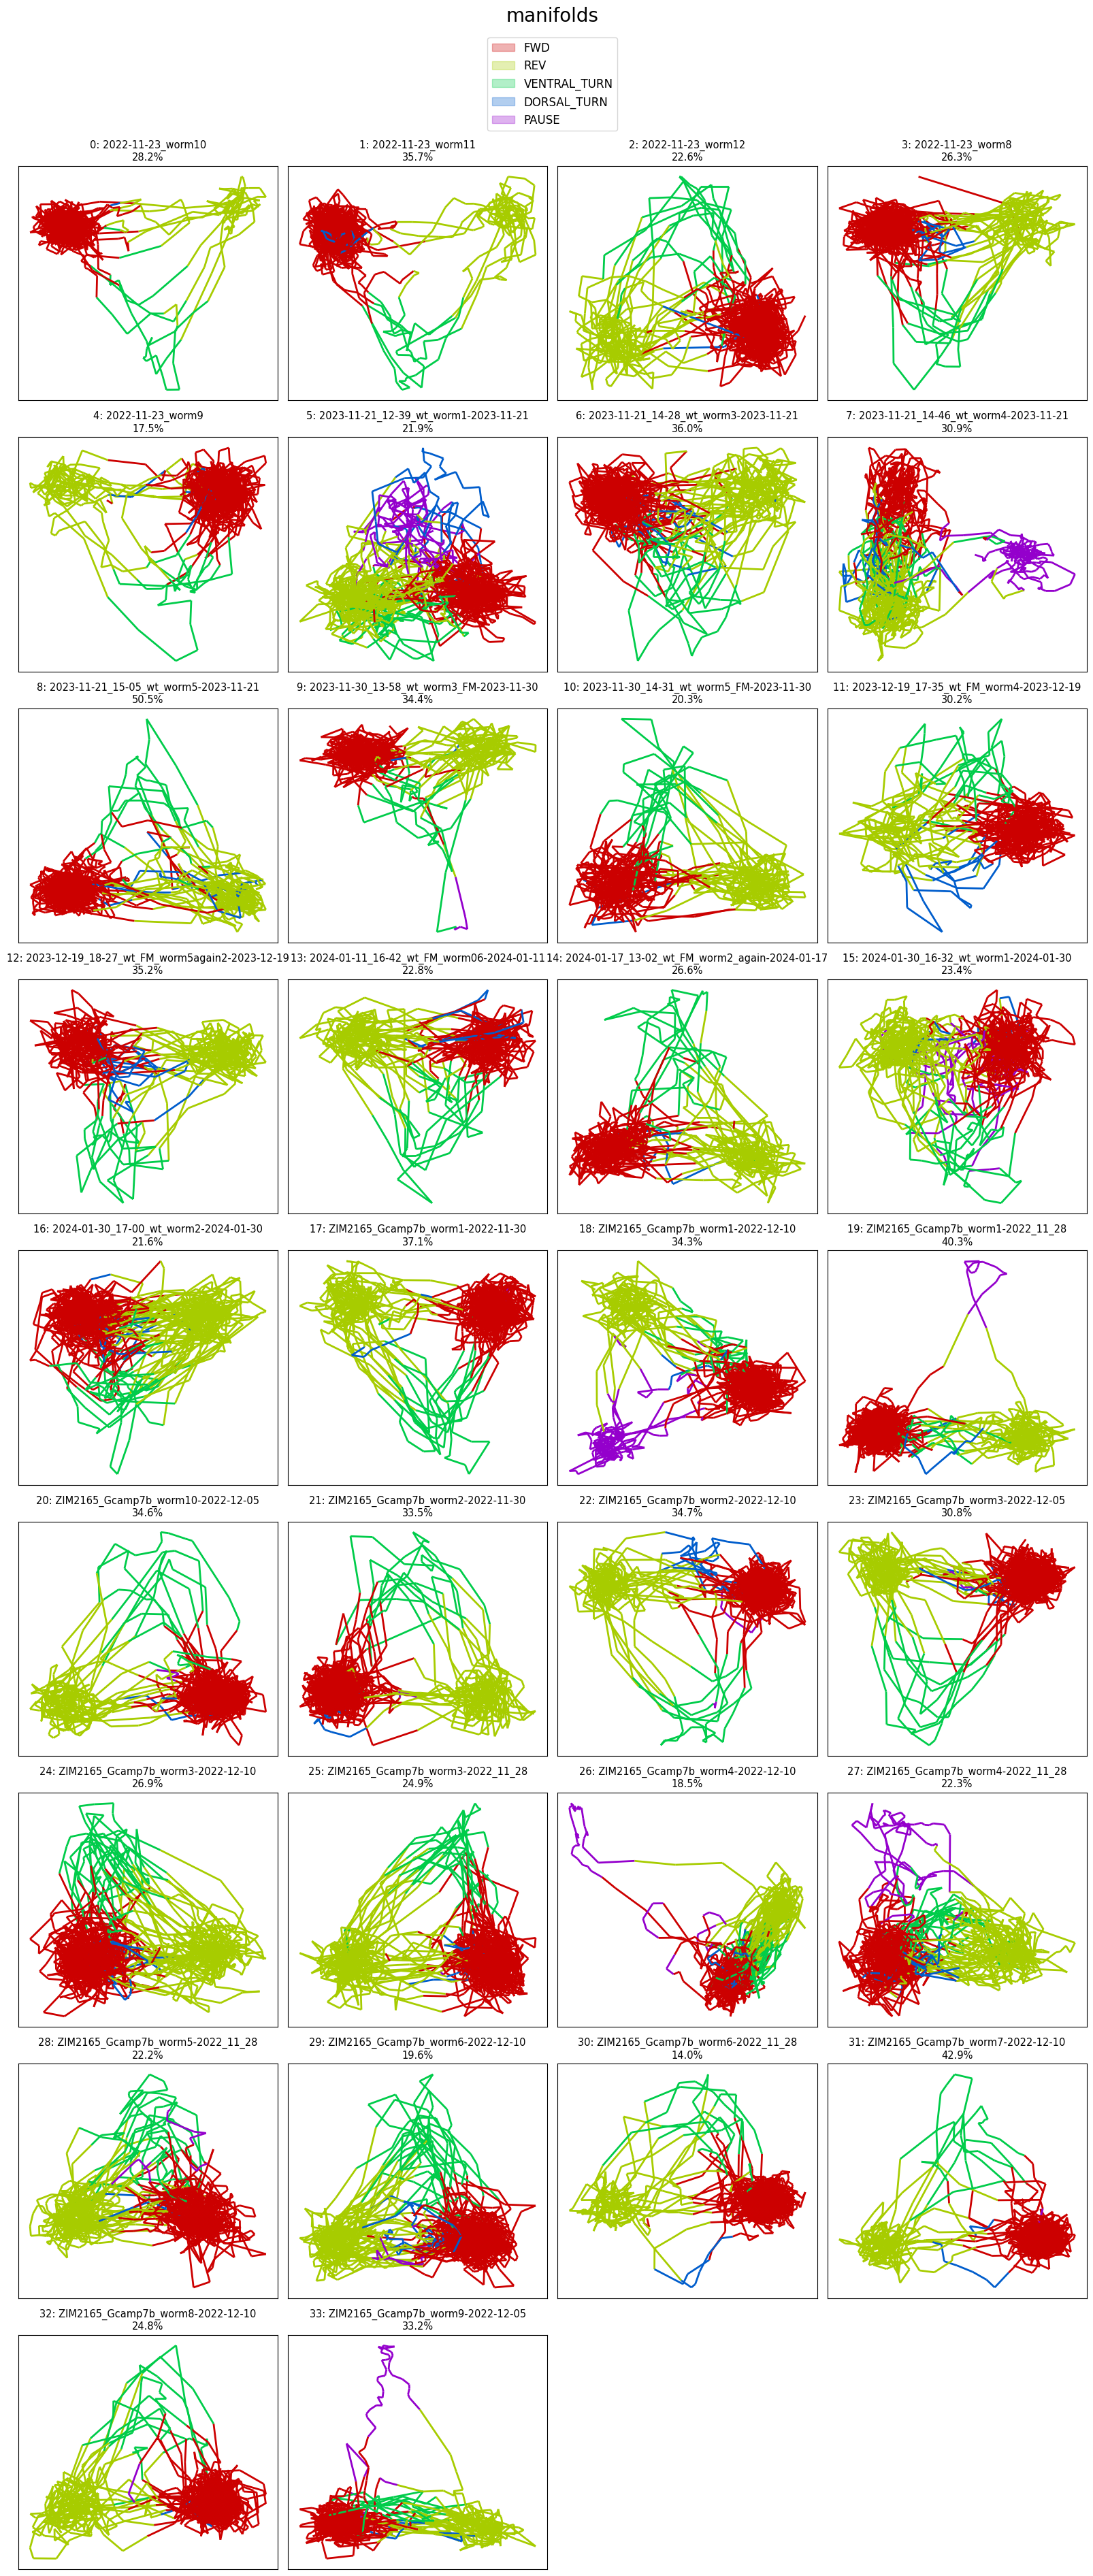

28.8%


In [19]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
						  vars_expl_mans, vars_expl_mans_rs if dims_preca > 0 else None,
						  save_name=f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA')

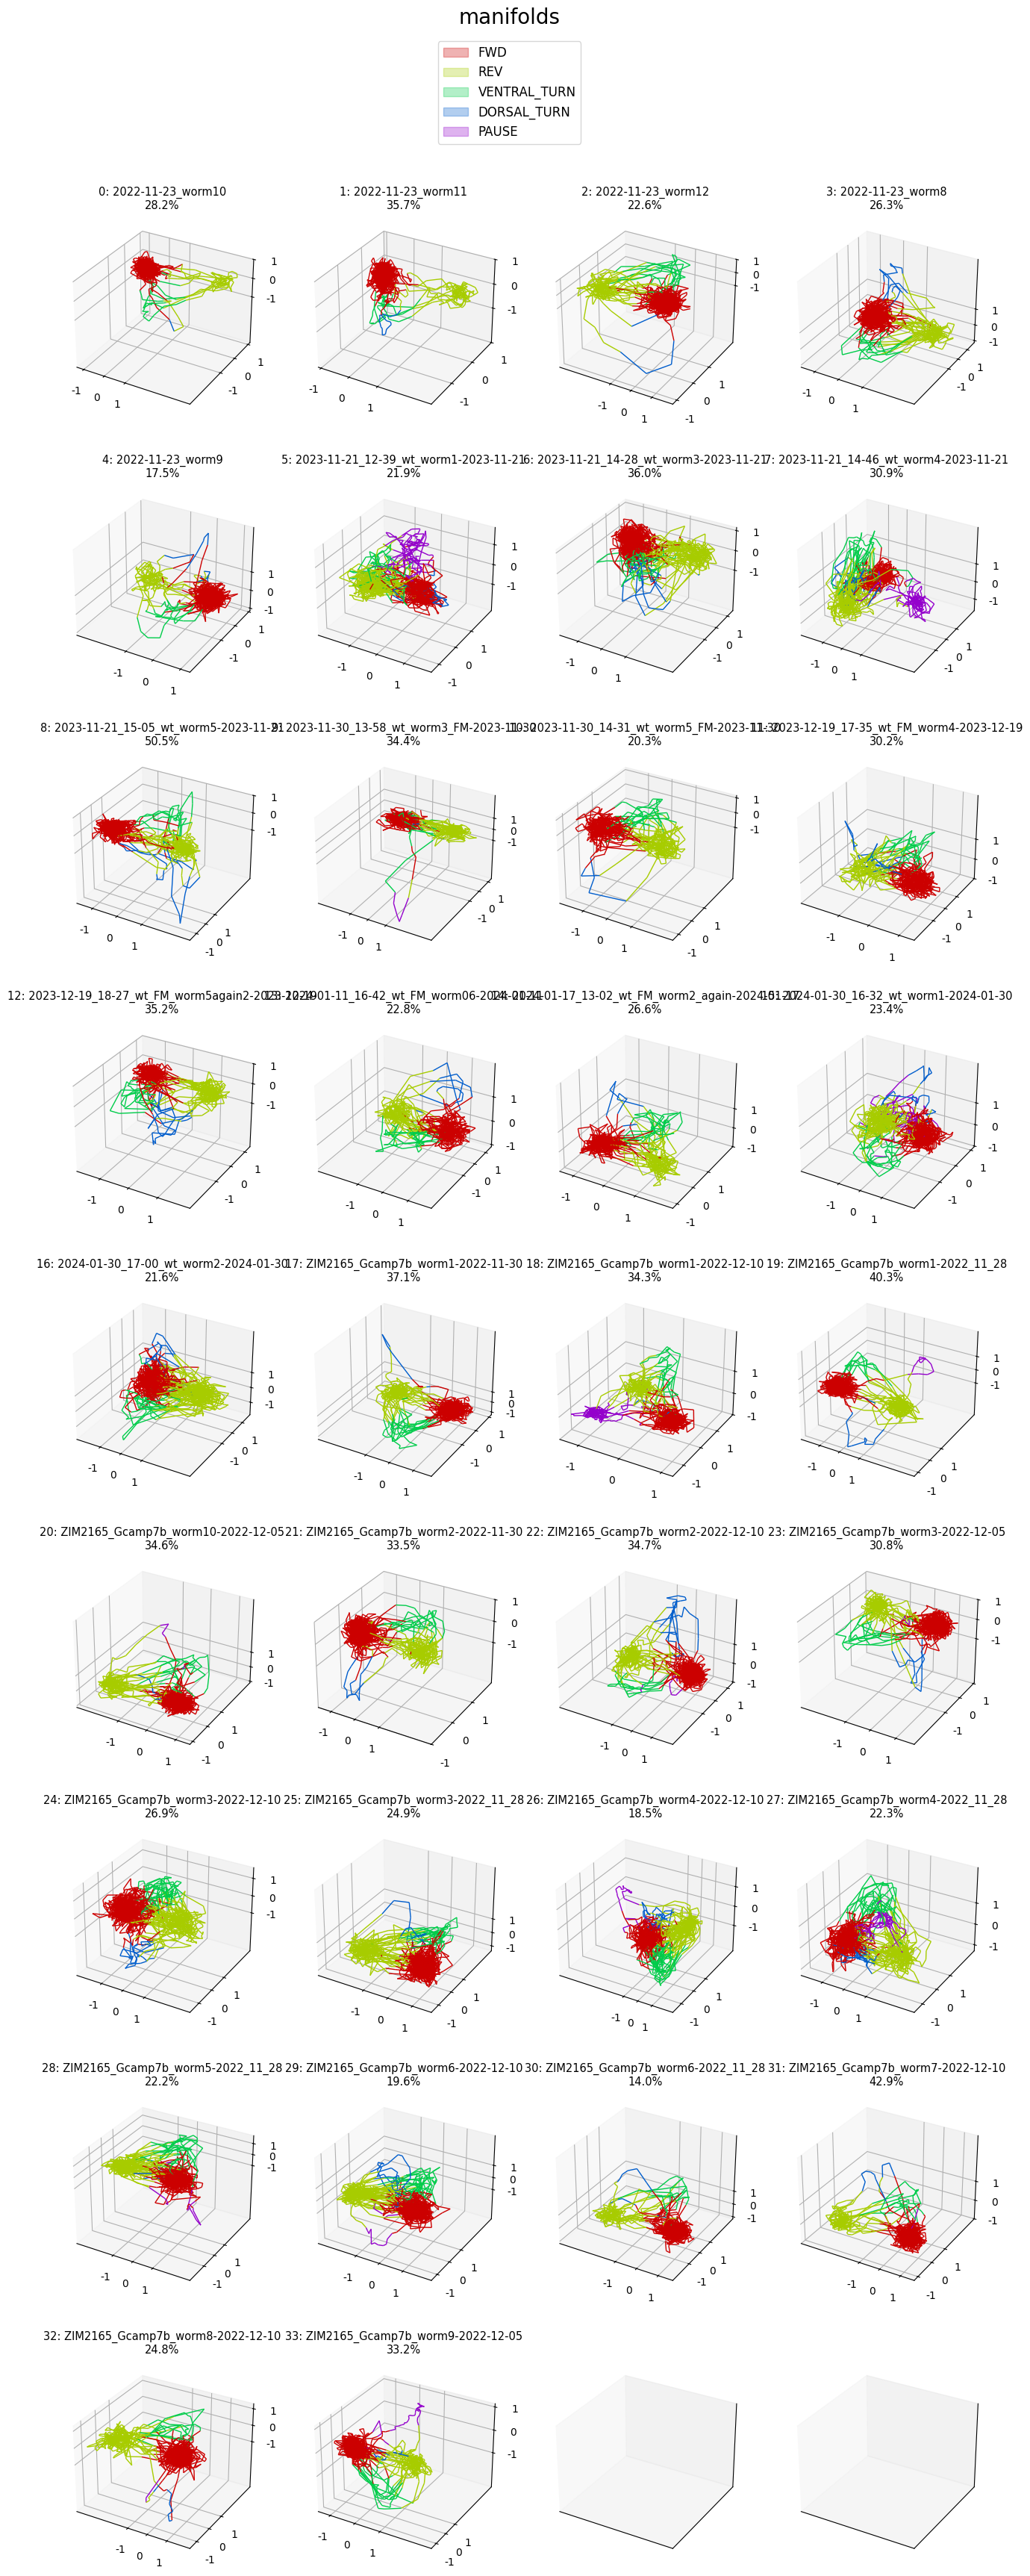

28.8%


In [20]:
plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
							 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
							 vars_expl_mans, vars_expl_mans_rs if dims_preca > 0 else None,
							 save_name=f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d')

In [ ]:
plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
								 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
								 vars_expl_mans, vars_expl_mans_rs if dims_preca > 0 else None,
								 animate=True, n_plots=None,
								 save_name=f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d')

In [ ]:
# traces_residual = [trace - trace_man for trace, trace_man in zip(traces, recos_manifold)]
#
# plot_utils.plot_traces('residuals',
# 					   discrete_states[file_ids.index(plot_id)]['REV'],
# 					   traces_residual[file_ids.index(plot_id)][selection_n],
# 					   n_plots=None, plots_per_row=1, ylimits=None)